In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset_path = r"C:\Users\user\Documents\E-Commerce-Customer-Business-Analytics\data\processed"

orders = pd.read_csv(dataset_path + r"\orders_cleaned.csv")
order_items = pd.read_csv(dataset_path + r"\order_items_cleaned.csv")
products = pd.read_csv(dataset_path + r"\products_cleaned.csv")
customers = pd.read_csv(dataset_path + r"\customers_cleaned.csv")
returns = pd.read_csv(dataset_path + r"\returns_cleaned.csv")

print("Advanced Business Analysis Ready!")

Advanced Business Analysis Ready!


In [2]:
print("ORDER ITEMS COLUMNS:")
print(order_items.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(products.columns.tolist())

ORDER ITEMS COLUMNS:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'item_revenue', 'item_cost', 'profit']

PRODUCTS COLUMNS:
['product_id', 'product_name', 'category', 'subcategory', 'brand', 'price', 'cost_price', 'discount_range', 'rating_average', 'rating_count', 'stock_quantity', 'product_launch_date', 'product_type', 'return_rate_baseline']


In [3]:
product_analysis = order_items.merge(
    products[["product_id", "product_name", "category"]],
    on="product_id"
)

product_summary = product_analysis.groupby(
    ["product_name", "category"]
).agg(
    Total_Quantity=("quantity", "sum"),
    Total_Revenue=("item_revenue", "sum"),
    Total_Profit=("profit", "sum")
).reset_index()

top_products = product_summary.sort_values(
    "Total_Profit", ascending=False
)

print(top_products.head(10).round(2))

                               product_name        category  Total_Quantity  \
159  Gandhi-Lanka Ultra Storage & Container  Home & Kitchen           11062   
476             Setty Essential Formal Shoe        Footwear            8322   
96                Chanda Deluxe Winter Wear         Fashion           17710   
481                      Shah Basic Handbag            Bags           11007   
108          Chaudhry, Advanced Smartwatche     Electronics            9048   
413       Ramakrishnan Advanced Winter Wear         Fashion            5084   
246             Kar-Issac Premium Kids Wear         Fashion            9951   
493              Solanki, Basic Winter Wear         Fashion           14324   
78             Boase, Ultra Air Conditioner      Appliances            1543   
126        Dash, Deluxe Sandals & Flip Flop        Footwear            2624   

     Total_Revenue  Total_Profit  
159   8.141222e+07   16809917.96  
476   3.961464e+07   12709450.11  
96    3.128365e+07   1015

In [4]:
category_profit = product_analysis.groupby("category").agg(
    Revenue=("item_revenue", "sum"),
    Profit=("profit", "sum")
).sort_values("Profit", ascending=False)

print(category_profit.round(2))

                             Revenue       Profit
category                                         
Fashion                 1.393936e+08  46192014.22
Home & Kitchen          1.580755e+08  28392024.89
Footwear                8.260349e+07  24298429.50
Bags                    5.591211e+07  15984391.42
Appliances              4.052333e+08  15743436.40
Furniture               1.470115e+08  14348527.85
Electronics             1.223619e+09   8450905.95
Health & Wellness       3.182433e+07   6957754.85
Beauty                  2.336538e+07   6190802.66
Sports                  2.652405e+07   5945316.96
Toys                    2.434126e+07   5302530.64
Watches                 2.200641e+07   4232577.11
Personal Care           1.455045e+07   3587947.95
Musical Instruments     2.095935e+07   2571868.11
Mobile Accessories      1.073165e+07   2121246.15
Books                   2.003688e+07   1917841.15
Stationery              8.057862e+06   1393946.92
Baby Care               6.811130e+06   1143665.64


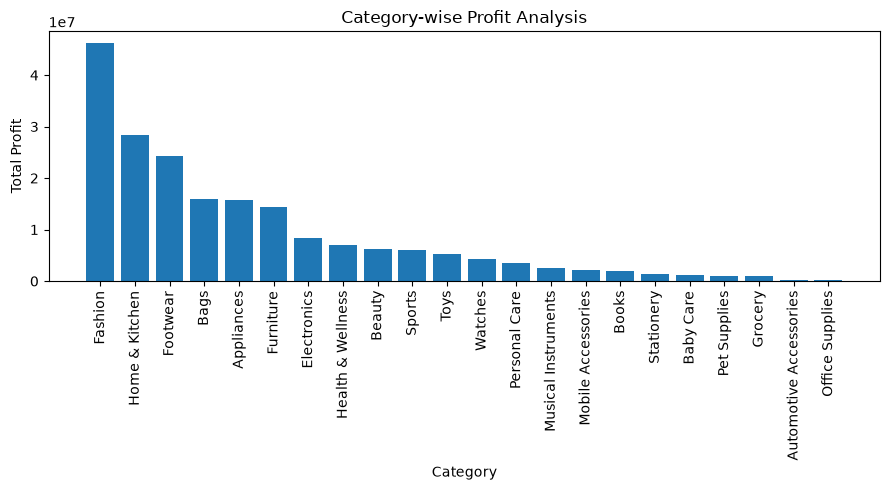

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(category_profit.index, category_profit["Profit"])

plt.title("Category-wise Profit Analysis")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [7]:
category_profit["Profit_Margin_%"] = (
    category_profit["Profit"] / category_profit["Revenue"] * 100
).round(2)

print(category_profit.round(2))

                             Revenue       Profit  Profit_Margin_%
category                                                          
Fashion                 1.393936e+08  46192014.22            33.14
Home & Kitchen          1.580755e+08  28392024.89            17.96
Footwear                8.260349e+07  24298429.50            29.42
Bags                    5.591211e+07  15984391.42            28.59
Appliances              4.052333e+08  15743436.40             3.89
Furniture               1.470115e+08  14348527.85             9.76
Electronics             1.223619e+09   8450905.95             0.69
Health & Wellness       3.182433e+07   6957754.85            21.86
Beauty                  2.336538e+07   6190802.66            26.50
Sports                  2.652405e+07   5945316.96            22.41
Toys                    2.434126e+07   5302530.64            21.78
Watches                 2.200641e+07   4232577.11            19.23
Personal Care           1.455045e+07   3587947.95            2

In [10]:
print(returns.columns.tolist())

['return_id', 'order_id', 'customer_id', 'product_id', 'return_date', 'return_reason', 'refund_amount', 'return_status']


In [11]:
return_analysis = returns.merge(
    products[["product_id", "category"]],
    on="product_id"
)

category_returns = return_analysis["category"].value_counts()

print("CATEGORY-WISE ACTUAL RETURNS:")
print(category_returns)

CATEGORY-WISE ACTUAL RETURNS:
category
Fashion                   3185
Electronics               1232
Footwear                  1205
Home & Kitchen            1102
Appliances                 783
Bags                       692
Toys                       550
Health & Wellness          441
Grocery                    392
Books                      350
Beauty                     349
Mobile Accessories         331
Stationery                 321
Personal Care              266
Sports                     190
Furniture                  186
Watches                    117
Baby Care                  113
Musical Instruments         83
Automotive Accessories      73
Pet Supplies                69
Office Supplies             45
Name: count, dtype: int64


In [12]:
print(returns["return_reason"].value_counts())

return_reason
Size issue                 2201
Changed mind               1984
Product damaged            1933
Quality issue              1692
Product not as expected    1442
Wrong product              1394
Late delivery               960
Other                       469
Name: count, dtype: int64


In [13]:
top_products.to_csv(dataset_path + r"\product_profit_analysis.csv", index=False)

category_profit.to_csv(dataset_path + r"\category_profit_analysis.csv")

return_analysis.to_csv(dataset_path + r"\product_return_analysis.csv", index=False)

print("Advanced Business Analysis Saved Successfully!")

Advanced Business Analysis Saved Successfully!
